# EBM entrenado con PCD en MNIST



In [ ]:
import sys
from pathlib import Path

project_root = Path.cwd().parents[0]
sys.path.append(str(project_root))
print("Project root:", project_root)

import random
import numpy as np
import torch
import matplotlib.pyplot as plt

from data import get_mnist_loaders

from ebm.models import ScoreUNet
from ebm.sampling import langevin_sampling, ReplayBuffer
from ebm.training import train_energy_model_pcd
from utils import (
    to_01,
    noise_like_images,
    plot_image_grid,
    plot_image_evolution
)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("device:", device)

Project root: /home/usuario/Documentos/TFG
device: cuda


## Configuración

Todos los hiperparámetros en un solo diccionario: así puedes guardar exactamente qué usaste en cada experimento
(se guarda junto a los checkpoints). `QUICK_TEST = True` hace una pasada corta para comprobar que todo corre
antes de lanzar el entrenamiento largo.

In [ ]:
QUICK_TEST = False   # True: 2 épocas de 20 iteraciones, para comprobar que el notebook corre

CFG = dict(
    seed            = 42,
    # datos
    batch_size      = 128,
    data_noise      = 0.005,   
    # red
    hidden          = 32,
    spectral_norm   = False,  
    # buffer PCD
    buffer_size     = 8192,
    reinit_prob     = 0.05,    
    # SGLD (entrenamiento)
    sgld_steps      = 60,
    sgld_step_size  = 10.0,
    sgld_noise      = 0.005,
    sgld_grad_clip  = 0.03,    
    gen_steps       = 256,
    # optimización
    alpha           = 0.1,     
    lr              = 1e-4,
    betas           = (0.0, 0.999),
    lr_gamma        = 0.97,    
    grad_clip_norm  = 0.1,
    epochs          = 60,
    max_iters_per_epoch = None,
    # monitorización
    vis_every       = 5,       
    ckpt_dir        = "../checkpoints/pcd",
    # results
    results_dir     = "../results/pcd",
)

if QUICK_TEST:
    CFG.update(epochs=2, max_iters_per_epoch=20, vis_every=1, gen_steps=60)

set_seed(CFG["seed"])
IMG_SHAPE = (1, 28, 28)
CFG

{'seed': 42,
 'batch_size': 128,
 'data_noise': 0.005,
 'hidden': 32,
 'spectral_norm': False,
 'buffer_size': 8192,
 'reinit_prob': 0.05,
 'sgld_steps': 60,
 'sgld_step_size': 10.0,
 'sgld_noise': 0.005,
 'sgld_grad_clip': 0.03,
 'gen_steps': 256,
 'alpha': 0.1,
 'lr': 0.0001,
 'betas': (0.0, 0.999),
 'lr_gamma': 0.97,
 'grad_clip_norm': 0.1,
 'epochs': 60,
 'max_iters_per_epoch': None,
 'vis_every': 5,
 'ckpt_dir': '../checkpoints/dsm',
 'results_dir': '../results/dsm'}

## Datos

In [3]:
train_loader, test_loader = get_mnist_loaders(
    batch_size=CFG["batch_size"],
    normalize=True,
    num_workers=2,
)

x_real, _ = next(iter(train_loader))

print(
    x_real.shape,
    x_real.min().item(),
    x_real.max().item(),
)

torch.Size([128, 1, 28, 28]) -1.0 1.0


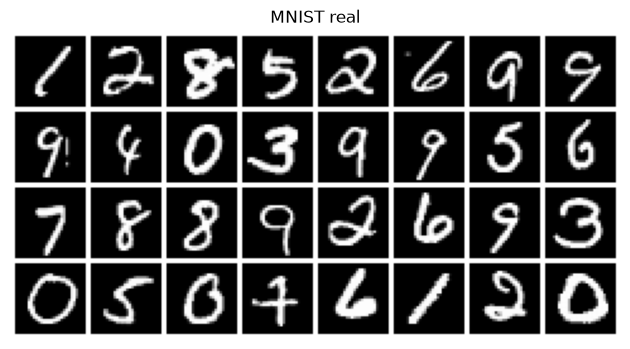

In [ ]:
fig, ax = plot_image_grid(
    to_01(x_real[:32]),
    figsize=(8, 4),
    n_cols=8,
)

ax.set_title("MNIST real")
plt.show()

## Red de energía

In [5]:
model = EnergyModelPCD(
    hidden=CFG["hidden"],
    spectral_norm=CFG["spectral_norm"],
).to(device)

print(model)
print("parámetros:", sum(p.numel() for p in model.parameters()))

EnergyModelPCD(
  (net): Sequential(
    (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(2, 2), padding=(4, 4))
    (1): Swish()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): Swish()
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): Swish()
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): Swish()
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=256, out_features=64, bias=True)
    (10): Swish()
    (11): Linear(in_features=64, out_features=1, bias=True)
  )
)
parámetros: 76993


## Muestreador SGLD

In [6]:
sampler_kwargs = dict(
    n_steps=CFG["sgld_steps"],
    step_size=CFG["sgld_step_size"],
    noise_scale=CFG["sgld_noise"],
    grad_clip=CFG["sgld_grad_clip"],
)

## Replay buffer (las cadenas persistentes)

In [7]:
buffer = ReplayBuffer(
    size=CFG["buffer_size"],
    image_shape=IMG_SHAPE,
    reinit_prob=CFG["reinit_prob"],
    device=device,
)

## Entrenamiento

In [10]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=CFG["lr"],
    betas=CFG["betas"],
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=1,
    gamma=CFG["lr_gamma"],
)

# Lotes fijos para que las métricas por época sean comparables.
x_test_fixed = next(iter(test_loader))[0][:256].to(device)
x_noise_fixed = noise_like_images(1024, image_shape=IMG_SHAPE, device=device)
gen_init_fixed = noise_like_images(16, image_shape=IMG_SHAPE, device=device)  

hist_it = {
    key: []
    for key in ["loss", "cd", "reg", "e_real", "e_fake"]
}

hist_ep = {
    key: []
    for key in ["epoch", "e_test", "e_noise", "e_buffer", "lr", "time_s"]
}

In [ ]:
hist_it, hist_ep = train_energy_model_pcd(
    model=model,
    data_loader=train_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    langevin_sampler=langevin_sampling,
    replay_buffer=buffer,
    device=device,
    sampler_kwargs=sampler_kwargs,
    config=CFG,
    hist_it=hist_it,
    hist_ep=hist_ep,
    x_test_fixed=x_test_fixed,
    x_noise_fixed=x_noise_fixed,
    gen_init_fixed=gen_init_fixed,
)

## Curvas de entrenamiento

In [ ]:
def smooth(v, w=50):
    v = np.asarray(v, dtype=float)
    if len(v) < w: return v
    return np.convolve(v, np.ones(w) / w, mode="valid")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(smooth(hist_it["cd"]), label="CD")
ax[0].plot(smooth(hist_it["reg"]), label="regularización")
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_title("Términos de la pérdida (media móvil)"); ax[0].set_xlabel("iteración"); ax[0].legend()

ax[1].plot(smooth(hist_it["e_real"]), label=r"$E(x^+)$ datos")
ax[1].plot(smooth(hist_it["e_fake"]), label=r"$E(x^-)$ muestras")
ax[1].set_title("Energías en entrenamiento"); ax[1].set_xlabel("iteración"); ax[1].legend()

ep = hist_ep["epoch"]
ax[2].plot(ep, hist_ep["e_test"], "o-", label="test")
ax[2].plot(ep, hist_ep["e_buffer"], "s-", label="buffer")
ax[2].plot(ep, hist_ep["e_noise"], "^-", label="ruido uniforme")
ax[2].set_yscale("symlog")
ax[2].set_title("Energía media por época"); ax[2].set_xlabel("época"); ax[2].legend()

plt.tight_layout(); plt.show()

## Generación desde ruido y evolución de la cadena

Se parte de ruido uniforme (sin buffer) y se aplican `gen_steps` pasos. Cada fila es una muestra; cada columna, un
instante de la cadena.

In [ ]:
set_seed(123)

steps_to_show = [0, 8, 16, 32, 64, 128, 192, 256]

x0 = noise_like_images(
    8,
    image_shape=IMG_SHAPE,
    device=device,
)

x_gen, snapshots, energies = langevin_sampling(
    model=model,
    x_init=x0,
    n_steps=256,
    step_size=CFG["sgld_step_size"],
    noise_scale=CFG["sgld_noise"],
    grad_clip=CFG["sgld_grad_clip"],
    save_steps=steps_to_show,
)

trajectory = torch.stack(
    [snapshots[step] for step in steps_to_show],
    dim=-1,
)

_ = plot_image_evolution(
    images=to_01(trajectory),
    n_images=8,
    n_intermediate_steps=range(len(steps_to_show)),
    figsize=(10, 10),
)

plt.show()

plt.figure(figsize=(6, 3))
plt.plot(energies)
plt.xlabel("paso SGLD")
plt.ylabel("E media")
plt.title("Energía a lo largo de la cadena")
plt.show()

In [ ]:
set_seed(7)

x_many = langevin_sampling(
    model=model,
    x_init=noise_like_images(
        64,
        image_shape=IMG_SHAPE,
        device=device,
    ),
    n_steps=CFG["gen_steps"],
    step_size=CFG["sgld_step_size"],
    noise_scale=CFG["sgld_noise"],
    grad_clip=CFG["sgld_grad_clip"],
)

# 64 samples generated from noise
fig, ax = plot_image_grid(
    images=to_01(x_many),
    figsize=(7, 7),
    n_cols=8,
)

ax.set_title(
    f"64 muestras desde ruido ({CFG['gen_steps']} pasos)"
)

plt.show()

# 64 samples from the persistent replay buffer
buffer_samples = buffer.random_view(64)

fig, ax = plot_image_grid(
    images=to_01(buffer_samples),
    figsize=(7, 7),
    n_cols=8,
)

ax.set_title(
    "64 cadenas del buffer persistente"
)

plt.show()

## Experimento: cadenas largas 

In [ ]:
set_seed(11)

long_steps = [0, 60, 256, 500, 1000, 2000]

_, snapshots_long, energies_long = langevin_sampling(
    model=model,
    x_init=noise_like_images(
        8,
        image_shape=IMG_SHAPE,
        device=device,
    ),
    n_steps=max(long_steps),
    step_size=CFG["sgld_step_size"],
    noise_scale=CFG["sgld_noise"],
    grad_clip=CFG["sgld_grad_clip"],
    save_steps=long_steps,
)

trajectory_long = torch.stack(
    [snapshots_long[step] for step in long_steps],
    dim=-1,
)

_ = plot_image_evolution(
    images=to_01(trajectory_long),
    n_images=8,
    n_intermediate_steps=range(len(long_steps)),
    figsize=(10, 10),
)

plt.show()

plt.figure(figsize=(6, 3))
plt.plot(
    energies_long,
    label="cadena larga",
)
plt.axhline(
    hist_ep["e_test"][-1],
    color="k",
    ls="--",
    label="E media de test",
)
plt.xlabel("paso SGLD")
plt.ylabel("E media")
plt.legend()
plt.title("Energía en cadena larga")
plt.show()

## Comprobación

In [ ]:
x_t = x_test_fixed
casos = {
    "test real":          x_t,
    "test + ruido 0.3":   (x_t + 0.3 * torch.randn_like(x_t)).clamp(-1, 1),
    "test volteado":      x_t.flip(dims=(2, 3)),
    "muestras generadas": x_many,
    "ruido uniforme":     x_noise_fixed[:256],
}

model.eval()
with torch.no_grad():
    energias = {k: model(v).cpu().numpy() for k, v in casos.items()}
model.train()

for k, v in energias.items():
    print(f"{k:20s} E media {v.mean():+9.3f}   std {v.std():8.3f}")

plt.figure(figsize=(9, 4))
plt.boxplot(list(energias.values()), showfliers=False)
plt.xticks(range(1, len(energias) + 1), list(energias.keys()), rotation=15)
plt.yscale("symlog"); plt.ylabel(r"$E_\theta(x)$")
plt.title("Distribución de energías"); plt.tight_layout(); plt.show()